# A2A 서버 & 클라이언트 테스트

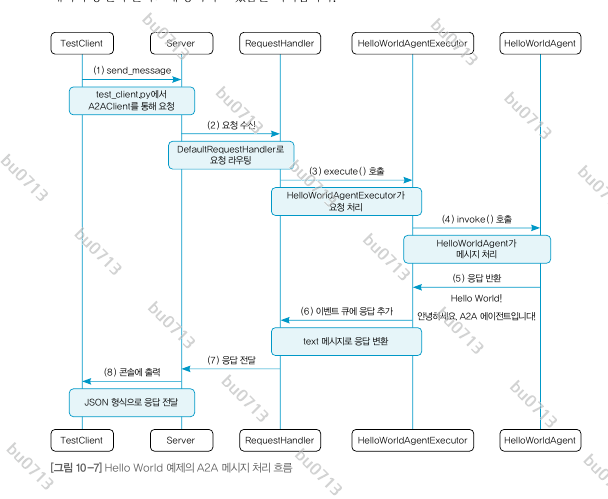

# 세팅

In [ ]:
from dotenv import load_dotenv

load_dotenv()

In [33]:
!  pip install -U "a2a-sdk" 


[notice] A new release of pip is available: 24.3.1 -> 26.1.2
[notice] To update, run: C:\Users\jino7\AppData\Local\Programs\Python\Python312\python.exe -m pip install --upgrade pip


In [29]:
! uv pip install --upgrade "protobuf>=5.29,<7"

Using Python 3.12.12 environment at: C:\Users\jino7\Desktop\llm_engineering-main\.venv
Resolved 1 package in 30ms
Audited 1 package in 0.54ms


# A2A 서버 실행

## 설명




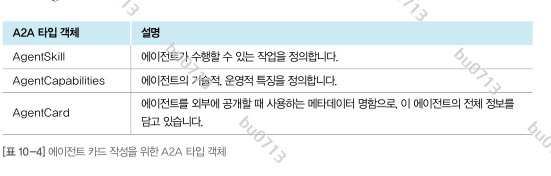

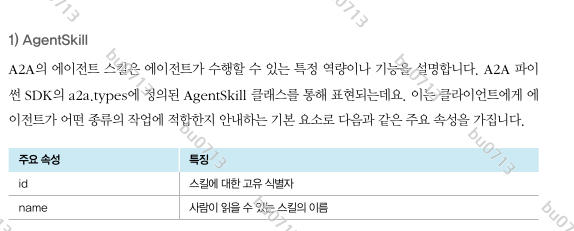

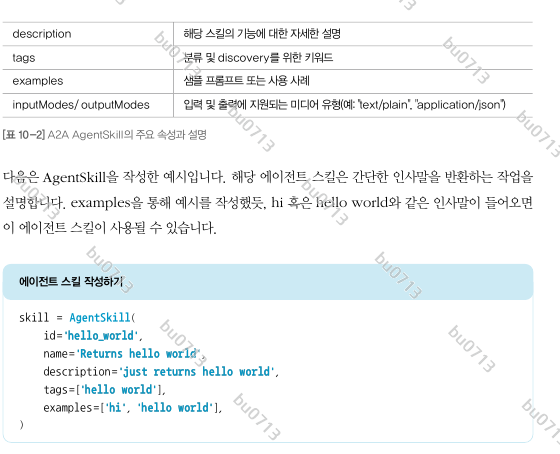

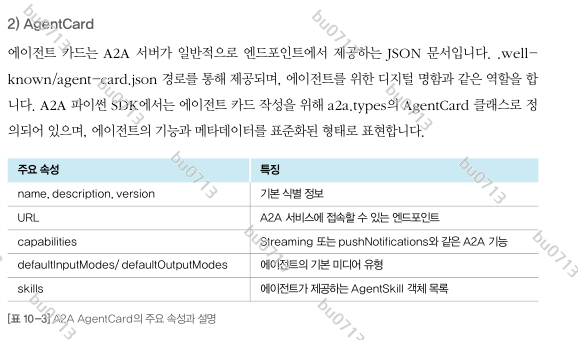

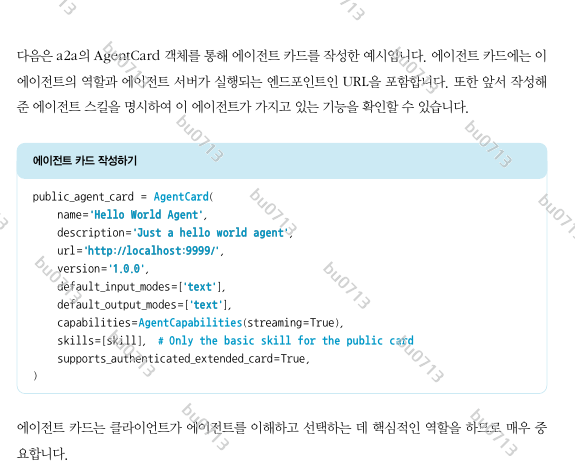

## 서버 코드

In [ ]:
import uvicorn
from starlette.applications import Starlette

from a2a.server.agent_execution import AgentExecutor, RequestContext
from a2a.server.events import EventQueue
from a2a.server.request_handlers import DefaultRequestHandler
from a2a.server.routes import create_agent_card_routes, create_jsonrpc_routes
from a2a.server.tasks import InMemoryTaskStore
from a2a.helpers import new_text_message
from a2a.types import AgentCapabilities, AgentCard, AgentInterface, AgentSkill
from a2a.utils import AGENT_CARD_WELL_KNOWN_PATH, DEFAULT_RPC_URL, TransportProtocol
from a2a.utils.errors import UnsupportedOperationError


# ============================================================
# 1. 에이전트 로직 계층
# ============================================================
class HelloWorldAgent:
    """고정된 인사말을 반환하는 에이전트"""

    async def invoke(self) -> str:
        # 입력과 무관하게 항상 동일한 문자열을 반환
        return "Hello World! 안녕하세요, A2A 에이전트입니다!"


# ============================================================
# 2. A2A 프로토콜 어댑터 계층 (AgentExecutor)
# ============================================================
class HelloWorldAgentExecutor(AgentExecutor):
    """A2A 요청을 받아 HelloWorldAgent를 호출하는 실행자"""

    def __init__(self):
        # 에이전트 인스턴스를 생성하여 보관
        self.agent = HelloWorldAgent()

    async def execute(
        self,
        context: RequestContext,   # 요청 컨텍스트 (사용자 메시지, task_id, context_id 보관)
        event_queue: EventQueue,   # 이 큐에 넣은 이벤트가 클라이언트 응답이 됨
    ) -> None:
        # 에이전트 로직을 실행하여 문자열 결과를 획득
        result = await self.agent.invoke()

        # 문자열을 role=ROLE_AGENT인 A2A Message로 변환한 뒤 큐에 적재
        await event_queue.enqueue_event(new_text_message(result))

    async def cancel(
        self,
        context: RequestContext,
        event_queue: EventQueue,
    ) -> None:
        # 취소 미지원을 A2A 표준 에러로 반환
        raise UnsupportedOperationError()


# ============================================================
# 3. 에이전트 카드 정의
# ============================================================
def create_agent_card() -> AgentCard:
    """에이전트의 메타데이터를 담은 AgentCard를 생성"""

    # AgentSkill: 에이전트가 수행 가능한 개별 작업 단위
    skill = AgentSkill(
        id='hello_world',                      # 스킬 고유 식별자
        name='Hello World 인사',                # 스킬 표시 이름
        description='간단한 인사말을 반환합니다',  # 스킬 설명
        tags=['인사', 'hello world', '기본'],    # 검색/라우팅용 키워드
        examples=['안녕', '안녕하세요', 'hi', 'hello'],  # 호출 예시 프롬프트
    )

    # AgentCapabilities: 프로토콜 수준의 기능 지원 여부 플래그
    capabilities = AgentCapabilities(
        streaming=False,           # SSE 스트리밍 응답 지원 여부
        push_notifications=False,  # 웹훅 푸시 알림 지원 여부
    )

    # AgentInterface: 접속 주소와 전송 바인딩을 정의 (1.0에서 신설)
    interface = AgentInterface(
        url='http://localhost:9999/',                     # JSON-RPC 요청을 받을 주소
        protocol_binding=TransportProtocol.JSONRPC.value, # 전송 바인딩 종류
        protocol_version='1.0',                           # A2A 프로토콜 버전
    )

    # AgentCard: 클라이언트가 조회하는 에이전트 명세서
    agent_card = AgentCard(
        name='Hello World 에이전트',
        description='A2A 프로토콜을 학습하기 위한 가장 간단한 에이전트입니다',
        version='1.0.0',
        supported_interfaces=[interface],  # 지원 인터페이스 목록 (url 필드를 대체)
        default_input_modes=['text'],      # 입력 형식
        default_output_modes=['text'],     # 출력 형식
        capabilities=capabilities,
        skills=[skill],
    )

    return agent_card


# ============================================================
# 4. 서버 조립 및 기동
# ============================================================
def main():
    """A2A 에이전트 서버를 구성하고 실행"""

    # 에이전트 카드 생성
    agent_card = create_agent_card()

    # JSON-RPC 메서드를 해석해 실행자를 호출하는 요청 처리기 생성
    request_handler = DefaultRequestHandler(
        agent_executor=HelloWorldAgentExecutor(),
        task_store=InMemoryTaskStore(),  # 태스크를 메모리에 보관하는 저장소
        agent_card=agent_card,           # 1.0에서 필수 인자로 추가됨
    )

    # GET /.well-known/agent-card.json 라우트 생성
    routes = create_agent_card_routes(
        agent_card=agent_card,
        card_url=AGENT_CARD_WELL_KNOWN_PATH,
    )

    # POST / JSON-RPC 라우트 생성 후 기존 라우트 목록에 추가
    routes += create_jsonrpc_routes(
        request_handler=request_handler,
        rpc_url=DEFAULT_RPC_URL,
    )

    # 생성된 라우트로 Starlette ASGI 앱을 직접 구성
    app = Starlette(routes=routes)

    # uvicorn으로 서빙
    uvicorn.run(app, host='0.0.0.0', port=9999)


if __name__ == '__main__':
    main()

터미날에서 실행

uv pip install --upgrade "protobuf>=5.29,<7"

In [ ]:
 python a2a_server.py 

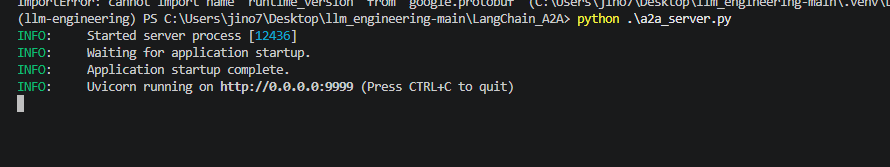

# A2A 클라이언트 구축

In [13]:
from uuid import uuid4
import httpx
from a2a.client import A2ACardResolver, create_client
from a2a.helpers import get_stream_response_text
from a2a.types import Message, Part, Role, SendMessageRequest

# 에이전트 카드를 조회할 베이스 URL
agent_url = 'http://localhost:9999'

# 카드 조회용 비동기 HTTP 클라이언트 생성
httpx_client = httpx.AsyncClient()

# 카드 리졸버 생성 (기본 경로: /.well-known/agent-card.json)
resolver = A2ACardResolver(httpx_client=httpx_client, base_url=agent_url)

# 서버에서 AgentCard를 다운로드
agent_card = await resolver.get_agent_card()

# 카드에 담긴 메타데이터를 출력
print(f"\n에이전트 정보:")
print(f"   - 이름: {agent_card.name}")
print(f"   - 설명: {agent_card.description}")
print(f"   - 버전: {agent_card.version}")
print(f"   - 스킬 개수: {len(agent_card.skills)}")

# 스킬 목록을 순회하며 이름/설명/예시를 출력
if agent_card.skills:
    print(f"\n   스킬 목록:")
    for skill in agent_card.skills:
        print(f"   • {skill.name}: {skill.description}")
        if skill.examples:
            print(f"     예시: {', '.join(skill.examples[:3])}")

# 카드 정보를 기반으로 클라이언트 생성 (전송 바인딩을 자동 선택)
client = await create_client(agent_card)

# 전송할 테스트 메시지 목록
test_messages = [
    "안녕하세요!",
    "Hello",
    "무엇을 할 수 있나요?",
]

for i, user_input in enumerate(test_messages, 1):
    print(f"\n[메시지 {i}/{len(test_messages)}]")
    print(f"👤 사용자: {user_input}")

    # 사용자 메시지 객체 생성 (message_id는 클라이언트가 생성)
    message = Message(
        message_id=uuid4().hex,
        role=Role.ROLE_USER,
        parts=[Part(text=user_input)],
    )

    # 요청 객체 생성 (JSON-RPC 봉투는 SDK가 내부에서 처리)
    request = SendMessageRequest(message=message)

    # 응답은 StreamResponse의 비동기 이터레이터로 반환됨
    async for response in client.send_message(request):
        # StreamResponse에서 텍스트만 추출
        text = get_stream_response_text(response)
        if text:
            print(f"🤖 에이전트: {text}")

# 연결 종료
await client.close()
await httpx_client.aclose()


에이전트 정보:
   - 이름: Hello World 에이전트
   - 설명: A2A 프로토콜을 학습하기 위한 가장 간단한 에이전트입니다
   - 버전: 1.0.0
   - 스킬 개수: 1

   스킬 목록:
   • Hello World 인사: 간단한 인사말을 반환합니다
     예시: 안녕, 안녕하세요, hi

[메시지 1/3]
👤 사용자: 안녕하세요!
🤖 에이전트: Hello World! 안녕하세요, A2A 에이전트입니다!

[메시지 2/3]
👤 사용자: Hello
🤖 에이전트: Hello World! 안녕하세요, A2A 에이전트입니다!

[메시지 3/3]
👤 사용자: 무엇을 할 수 있나요?
🤖 에이전트: Hello World! 안녕하세요, A2A 에이전트입니다!


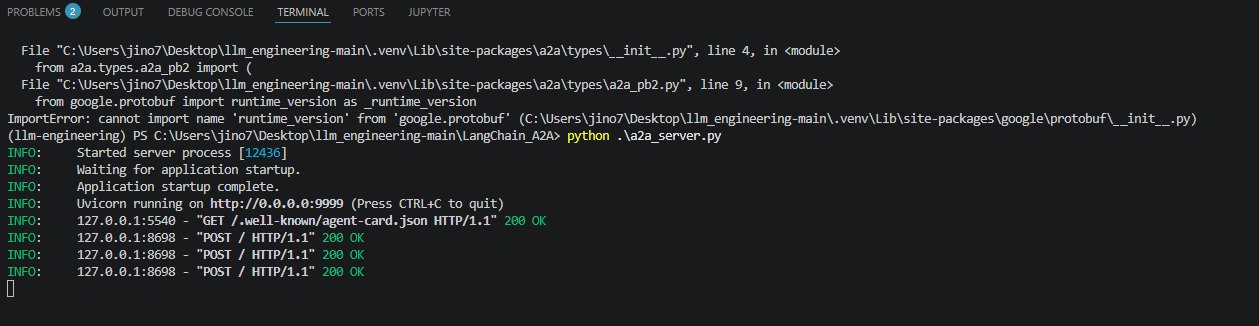

# A2A 서버 LangCahin agent 연결

In [1]:
# [셀 2] 임포트 및 설정
from typing import Any

import httpx
from a2a.client import ClientConfig, create_client
from a2a.helpers import get_stream_response_text, new_text_message
from a2a.types import Role, SendMessageRequest

from langchain.agents import create_agent
from langchain.tools import tool
from langchain_openai import ChatOpenAI

# A2A 서버의 베이스 URL (에이전트 카드는 기본 경로 /.well-known/agent-card.json 에서 조회됨)
A2A_BASE_URL = "http://localhost:9999"

In [3]:
# [셀 3] A2A 서버 호출을 LangChain 툴로 래핑
@tool
async def hello_world_agent(query: str) -> str:
    """원격 A2A 인사 에이전트에게 메시지를 보내고 응답 텍스트를 받아온다. 인사 요청 시 사용한다."""
    # 툴 호출 1회 동안만 유지되는 HTTP 클라이언트를 생성
    async with httpx.AsyncClient(timeout=30.0) as http_client:
        # A2A_BASE_URL의 AgentCard를 조회해 그에 맞는 transport로 클라이언트를 생성
        client = await create_client(
            agent=A2A_BASE_URL,
            client_config=ClientConfig(streaming=False, httpx_client=http_client),
        )
        # 텍스트 단일 Part를 가진 사용자 메시지를 생성해 요청으로 감쌈
        request = SendMessageRequest(message=new_text_message(query, role=Role.ROLE_USER))
        # StreamResponse를 순회하며 텍스트만 추출
        texts = [get_stream_response_text(r) async for r in client.send_message(request)]
    # 빈 문자열을 제외하고 줄바꿈으로 연결해 반환
    return "\n".join(filter(None, texts))

In [4]:
# [셀 5] 툴 단독 동작 확인 (에이전트 없이 A2A 연결만 검증)
# 셀에서 await를 직접 사용
print(await hello_world_agent.ainvoke({"query": "안녕하세요"}))

Hello World! 안녕하세요, A2A 에이전트입니다!


In [5]:
# [셀 6] LangChain 에이전트 구성
llm = ChatOpenAI(model="gpt-5-mini", temperature=0)

agent = create_agent(
    model=llm,
    tools=[hello_world_agent],
    system_prompt=(
        "너는 사용자의 요청을 처리하는 에이전트다. "
        "인사말이 필요한 요청은 hello_world_agent 툴을 호출해 원격 A2A 에이전트의 응답을 받아 전달해라."
    ),
)

In [6]:
# [셀 7] 에이전트 실행
result = await agent.ainvoke(
    {"messages": [{"role": "user", "content": "원격 에이전트한테 인사 좀 시켜줘"}]}
)

# 마지막 메시지가 최종 응답
print(result["messages"][-1].content)

원격 에이전트 응답: Hello World! 안녕하세요, A2A 에이전트입니다!


In [7]:
# [셀 8] 스트리밍 출력으로 중간 단계 확인 (선택)
async for step in agent.astream(
    {"messages": [{"role": "user", "content": "인사해줘"}]},
    stream_mode="values",
):
    step["messages"][-1].pretty_print()

================================ Human Message =================================

인사해줘
================================== Ai Message ==================================
Tool Calls:
  hello_world_agent (call_OLf1QnJZBN8mFVZYdKnORIty)
 Call ID: call_OLf1QnJZBN8mFVZYdKnORIty
  Args:
    query: 인사해줘
================================= Tool Message =================================
Name: hello_world_agent

Hello World! 안녕하세요, A2A 에이전트입니다!
================================== Ai Message ==================================

Hello World! 안녕하세요, A2A 에이전트입니다!
